# Home Credit: from payment histories to default-risk ranking

A loan application is one row; its credit history spans several tables. This notebook examines how application ratios and applicant-level historical aggregates feed a cross-validated LightGBM model, then checks the saved out-of-fold predictions and complete test output.

The default experiment uses **five fixed-seed stratified folds**. It checks target balance, out-of-fold coverage, model reload and fold variation. A separately recorded KFold benchmark scored **0.79641 public / 0.79065 private** on Kaggle (2026-11-08).

The competition evaluates **ROC AUC**. Out-of-fold AUC and Kaggle public/private scores measure different populations and are reported separately. See [results](../docs/results.md) for the current benchmark comparison.

Prerequisites: the locked environment and authorized competition files. Set `HOME_CREDIT_DATA_DIR`; keep data and experiment outputs outside Git.

## Applicants, credit histories and the target

`SK_ID_CURR` identifies the applicant. `TARGET=1` indicates payment difficulty under the competition definition. Child tables contain bureau accounts, monthly balances, previous applications and payments. Joining raw child rows directly would duplicate applicants, so each history is aggregated to applicant level first.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score, roc_curve

from home_credit.cli import validate
from home_credit.pipeline import analyze, evaluate, fit_cv, prepare, read_features, sha256, validate_submission

PROJECT = Path.cwd()
if not (PROJECT / "pyproject.toml").exists():
    PROJECT = PROJECT.parent
DATA_DIR = Path(os.environ.get("HOME_CREDIT_DATA_DIR", PROJECT / "data"))
CACHE = Path(os.environ.get("HOME_CREDIT_CACHE", PROJECT / ".local/cache"))
RUN_DIR = Path(os.environ.get("HOME_CREDIT_RUN_DIR", PROJECT / ".local/stratified-baseline"))
CONFIG = json.loads((PROJECT / "configs/baseline.json").read_text())
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
validation = validate(DATA_DIR)
print(validation)

{'train_rows': 307511, 'test_rows': 48744, 'target_rate': 0.08072881945686496, 'sample_id_order_match': True}


Most applicants do not have the positive target. AUC evaluates ranking across classes; accuracy alone could look high for a model that always predicts the majority class. Class balance also matters when interpreting probability distributions.

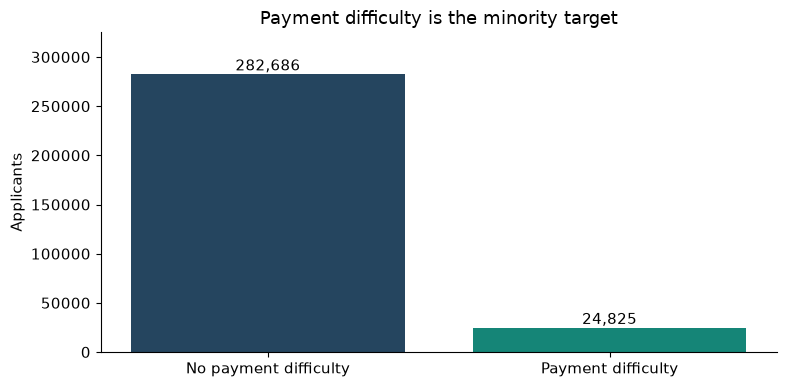

In [2]:
application = pd.read_csv(DATA_DIR / "application_train.csv",
                          usecols=["SK_ID_CURR", "TARGET", "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"])
counts = application.TARGET.value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(["No payment difficulty", "Payment difficulty"], counts.values, color=["#25455f", "#158577"])
ax.set(ylabel="Applicants", title="Payment difficulty is the minority target")
for i, value in enumerate(counts):
    ax.text(i, value, f"{value:,}", ha="center", va="bottom")
ax.margins(y=0.15)
fig.tight_layout()
plt.show()

## Relational feature construction

Application features include credit-to-annuity ratios and external-score summaries. Bureau balances are first aggregated by bureau account and then by applicant. Other child tables summarize prior credit decisions, delinquency and installment payment differences. Joins validate a unique aggregate per applicant.

The selected-feature recipe derives from the original repository's credited Aguiar/Grellier implementation. Four training rows with `CODE_GENDER=XNA` are excluded as in that recipe. Category vocabularies and organization-income medians use the combined unlabeled application population: this is a **transductive competition design**, not a claim of an inductive production lending model. No target values enter these aggregations. The historical exclusion list is fixed before this rerun; it is not selected using the current validation predictions.

In [3]:
if not CACHE.exists():
    feature_receipt = prepare(DATA_DIR, CACHE)
frame, feature_receipt = read_features(CACHE)
print({"rows": len(frame), "labeled_rows": int(frame.TARGET.notna().sum()),
       "test_rows": int(frame.TARGET.isna().sum()),
       "columns": len(frame.columns), "cache_sha256": feature_receipt["cache_sha256"]})
assert frame.SK_ID_CURR.is_unique
assert len(frame.loc[frame.TARGET.isna()]) == validation["test_rows"]

{'rows': 356251, 'labeled_rows': 307507, 'test_rows': 48744, 'columns': 531, 'cache_sha256': '812abaa2004cfa530d662d3fd7ffa996f9ee71b1ff22b36e0ab3d88963ed89d4'}


## Five folds separate model fitting from validation

The default profile uses five shuffled StratifiedKFold applicant partitions with seed 1001. Each fold retains the overall target proportion; the seed is fixed before examining results. Each labeled applicant receives exactly one prediction from a model that did not train on that applicant. Early stopping monitors only that fold's validation AUC. The test prediction averages the five models.

Current LightGBM callbacks replace removed training arguments. Thread counts are bounded, model inputs exclude IDs and the target, and readable feature names are mapped to stable numeric column names for model serialization. The complete recipe is visible below. Training executes if a completed run is not already available; subsequent reads reuse and verify its recorded artifacts.

Early stopping selects the checkpoint using the same fold whose AUC is reported. Its labels are excluded from fitting tree gradients but participate in model selection, so this OOF result is a validation estimate with possible selection optimism, not an untouched nested outer-test estimate. A stricter design would use an inner stopping partition and keep the outer fold independent. The fixed feature list and settings also come from prior work on this competition.

In [4]:
print(json.dumps(CONFIG, indent=2))
if not RUN_DIR.exists():
    fit_cv(CACHE, RUN_DIR, CONFIG)
manifest = json.loads((RUN_DIR / "manifest.json").read_text())
assert manifest["status"] == "completed"
metrics = json.loads((RUN_DIR / "metrics.json").read_text())
print(metrics)

{
  "name": "stratified-baseline",
  "folds": 5,
  "stratified": true,
  "split_seed": 1001,
  "threads": 6,
  "max_rounds": 10000,
  "early_stopping_rounds": 200,
  "parameters": {
    "objective": "binary",
    "boosting_type": "gbdt",
    "learning_rate": 0.02,
    "num_leaves": 20,
    "feature_fraction": 0.9497036,
    "bagging_fraction": 0.8715623,
    "bagging_freq": 1,
    "max_depth": 8,
    "lambda_l1": 0.041545473,
    "lambda_l2": 0.0735294,
    "min_gain_to_split": 0.0222415,
    "min_sum_hessian_in_leaf": 60,
    "seed": 0,
    "verbosity": -1,
    "metric": "auc"
  }
}
{'oof_roc_auc': 0.7925749500292526, 'fold_auc_mean': 0.7925757387254583, 'train_rows': 307507, 'test_rows': 48744, 'features': 528}


## Label balance and fold variation

Stratification controls the target mix, not the difficulty of every held-out applicant. The analyzer independently reconstructs the configured assignments, checks unique applicant identity and complete OOF coverage, recomputes pooled AUC, and reports per-fold class counts, best iterations and score dispersion. It also retains covariate summaries for investigating weaker folds.

Fold standard deviation is descriptive. Folds share training data, so it is not a confidence interval or a guarantee about future populations.

,fold,validation_rows,positive_rows,negative_rows,positive_rate,roc_auc,best_iteration
0,1,61502,4965,56537,8.073%,0.78784,1989
1,2,61502,4965,56537,8.073%,0.79297,2175
2,3,61501,4965,56536,8.073%,0.79653,2442
3,4,61501,4965,56536,8.073%,0.79469,2825
4,5,61501,4965,56536,8.073%,0.79085,2224


{'pooled_oof_auc': 0.7925749500292526, 'fold_auc_mean': 0.7925757387254583, 'fold_auc_std': 0.0033772991222507927, 'auc_range': [0.787840122736154, 0.7965282162629563], 'repeatable_assignments': True, 'oof_coverage': 1.0, 'id_overlap': 0}


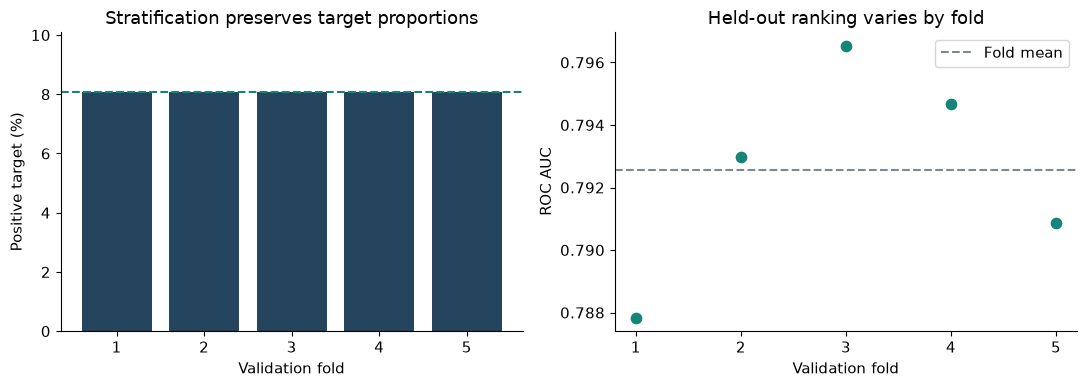

In [5]:
report = analyze(CACHE, RUN_DIR, PROJECT / ".local/analyses/stratified.json")
folds = pd.DataFrame(report["fold_metrics"])
display(folds[["fold", "validation_rows", "positive_rows", "negative_rows", "positive_rate",
               "roc_auc", "best_iteration"]].style.format({"positive_rate": "{:.3%}", "roc_auc": "{:.5f}"}))
print({"pooled_oof_auc": report["pooled_oof_roc_auc"],
       "fold_auc_mean": report["fold_auc_mean"], "fold_auc_std": report["fold_auc_std"],
       "auc_range": [report["fold_auc_min"], report["fold_auc_max"]],
       "repeatable_assignments": report["assignment_repeatable"],
       "oof_coverage": report["oof_coverage"], "id_overlap": report["id_overlap"]})
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(folds.fold, folds.positive_rate * 100, color="#25455f")
axes[0].axhline(report["positive_rate"] * 100, color="#158577", linestyle="--")
axes[0].set(xlabel="Validation fold", ylabel="Positive target (%)",
            title="Stratification preserves target proportions", ylim=(0, report["positive_rate"] * 125))
axes[1].scatter(folds.fold, folds.roc_auc, color="#158577", s=55)
axes[1].axhline(report["fold_auc_mean"], color="#7c8995", linestyle="--", label="Fold mean")
axes[1].set(xlabel="Validation fold", ylabel="ROC AUC", title="Held-out ranking varies by fold")
axes[1].legend()
for ax in axes:
    ax.set_xticks(folds.fold)
fig.tight_layout()
plt.show()

Equal target proportions do not guarantee equal feature distributions or equal AUC. The following summaries compare training, the weakest fold and the test population for selected numerical predictors. Missingness and medians are diagnostic views; they do not establish the cause of a weaker fold, and similar medians can conceal different tails or class-conditional distributions.

In [6]:
weakest_fold = str(report["weakest_fold"]["fold"])
contexts = []
for name, values in report["covariate_distributions"].items():
    contexts.append({"Feature": name, "Training median": values["training"]["median"],
                     "Weakest-fold median": values["validation_folds"][weakest_fold]["median"],
                     "Test median": values["test"]["median"],
                     "Training missing": values["training"]["missing_fraction"],
                     "Test missing": values["test"]["missing_fraction"]})
display(pd.DataFrame(contexts).style.format({"Training median": "{:.3f}",
    "Weakest-fold median": "{:.3f}", "Test median": "{:.3f}",
    "Training missing": "{:.2%}", "Test missing": "{:.2%}"}))
print({"weakest_fold": report["weakest_fold"]["fold"],
       "weakest_fold_auc": report["weakest_fold"]["roc_auc"],
       "positive_applicants": report["weakest_fold"]["positive_rows"]})

,Feature,Training median,Weakest-fold median,Test median,Training missing,Test missing
0,NEW_EXT_SOURCES_MEAN,0.525,0.524,0.520,0.06%,0.01%
1,NEW_CREDIT_TO_ANNUITY_RATIO,20.000,20.000,16.277,0.00%,0.05%
2,DAYS_BIRTH,-15750.000,-15747.500,-15785.000,0.00%,0.00%


{'weakest_fold': 1, 'weakest_fold_auc': 0.787840122736154, 'positive_applicants': 4965}


## Ranking performance across applicants

The ROC curve shows the trade-off between false positives and true positives over thresholds. Its AUC is computed on the complete out-of-fold vector, not averaged training predictions. This is internal validation; only an official Kaggle score supports a leaderboard comparison.

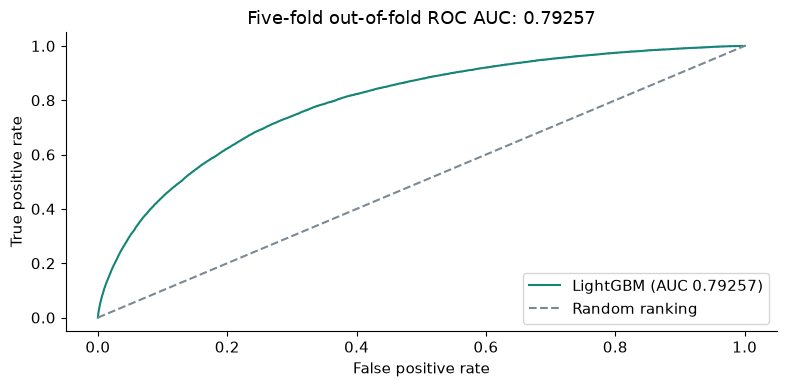

In [7]:
oof = pd.read_csv(RUN_DIR / "oof.csv")
assert oof.SK_ID_CURR.is_unique
assert len(oof) == int(frame.TARGET.notna().sum())
assert oof.fold.between(1, CONFIG["folds"]).all()
auc = roc_auc_score(oof.TARGET, oof.probability)
assert abs(auc - metrics["oof_roc_auc"]) < 1e-12
fig, ax = plt.subplots()
false_positive_rate, true_positive_rate, _ = roc_curve(oof.TARGET, oof.probability)
ax.plot(false_positive_rate, true_positive_rate, color="#158577", label=f"LightGBM (AUC {auc:.5f})")
ax.plot([0, 1], [0, 1], color="#7c8995", linestyle="--", label="Random ranking")
ax.set(title=f"Five-fold out-of-fold ROC AUC: {auc:.5f}",
       xlabel="False positive rate", ylabel="True positive rate")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

## Features used by the model

Gain importance summarizes how the fitted trees use features. It is not a causal effect, and correlated variables may share or exchange importance. The original names remain available even though the serialized model uses stable column identifiers.

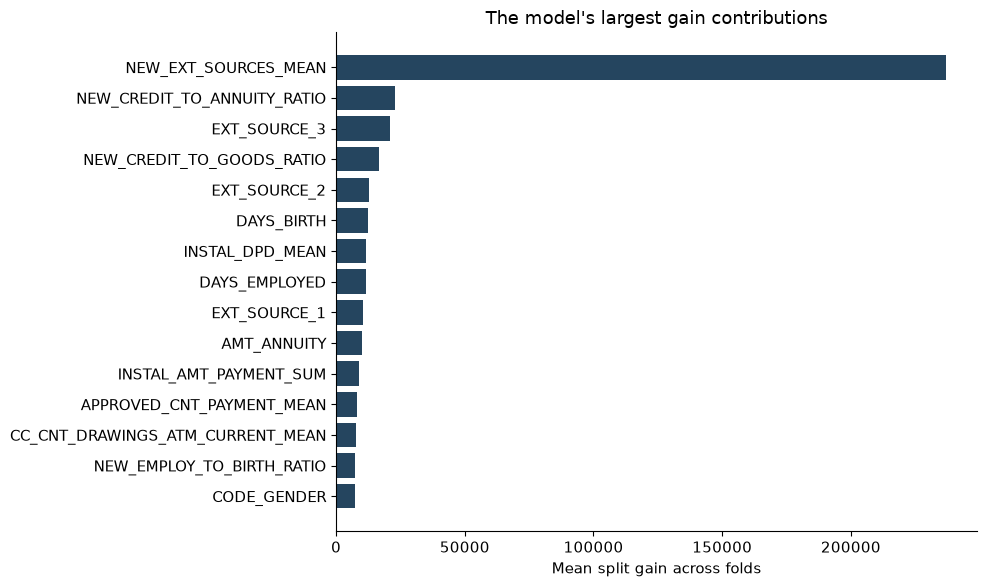

In [8]:
importance = pd.read_csv(RUN_DIR / "importance.csv")
top = importance.groupby("feature").gain.mean().nlargest(15).sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top.index, top.values, color="#25455f")
ax.set(xlabel="Mean split gain across folds", title="The model's largest gain contributions")
fig.tight_layout()
plt.show()

The external-score mean has the largest gain contribution in this run, followed by credit-to-annuity and other external-score features. This suggests testing the incremental value of historical features through a separate ablation; gain alone cannot establish their independent benefit.

## Reload models and verify the complete submission

Checkpoint evaluation reconstructs every validation prediction using the saved fold model and assignment. The submission contains one finite probability per official test applicant in the original order. Raw application records and prediction rows are not embedded in saved notebook outputs.

In [9]:
reloaded = evaluate(CACHE, RUN_DIR)
assert abs(reloaded["oof_roc_auc"] - auc) < 1e-12
submission = pd.read_csv(RUN_DIR / "submission.csv")
sample = pd.read_csv(DATA_DIR / "sample_submission.csv")
validate_submission(submission, sample.SK_ID_CURR)
print({"reloaded_oof_auc": reloaded["oof_roc_auc"],
       "submission_rows": len(submission),
       "official_id_order_matches": True,
       "submission_sha256": sha256(RUN_DIR / "submission.csv")})

{'reloaded_oof_auc': 0.7925749500292526, 'submission_rows': 48744, 'official_id_order_matches': True, 'submission_sha256': 'cddbc7afaf177018ae8a2f90748141cffe3d67c5f3e1bad2f5c1c26d294dfd19'}


The complete out-of-fold result, reload check and submission identity establish a reproducible experiment. The [benchmark record](../docs/results.md) separates this result from the original selected-feature model, the historical stacked model and any improved recipe.

For a controlled extension, keep the fold assignment fixed and change one feature family or regularization setting. Compare out-of-fold results before looking at leaderboard feedback. Additional experimentation on the same folds can overfit model selection; an untouched evaluation set is needed for a stronger generalization claim.

## Local tracking and Kaggle runs

`home-credit track` explicitly imports a completed run into an existing MLflow deployment. Shared storage and orchestration services are managed outside this repository. A Kaggle notebook can run the package offline and retain a portable run bundle; importing that bundle later does not require the hosted notebook to reach private services. See [execution](../docs/reproduction.md) and [Kaggle delivery](../docs/kaggle.md).

Set `HOME_CREDIT_TRACK=1` and `MLFLOW_TRACKING_URI` to import this completed run and its independently linked CV report. The shared platform must provision `kaggle/home-credit` first. Kaggle runs retain their portable artifacts without private-network access.

In [10]:
if os.environ.get("HOME_CREDIT_TRACK", "0") == "1":
    from mlflow import MlflowClient
    from home_credit.tracking import track

    tracking_uri = os.environ["MLFLOW_TRACKING_URI"]
    tracked = track(RUN_DIR, tracking_uri)
    client = MlflowClient(tracking_uri=tracking_uri)
    analysis_path = PROJECT / ".local/analyses/stratified.json"
    assert report["provenance"]["model_manifest_sha256"] == sha256(RUN_DIR / "manifest.json")
    analysis_sha = sha256(analysis_path)
    client.log_artifact(tracked["mlflow_run_id"], str(analysis_path),
                        artifact_path=f"diagnostics/{analysis_sha}")
    client.set_tag(tracked["mlflow_run_id"], "cv_report_sha256", analysis_sha)
    client.set_tag(tracked["mlflow_run_id"], "cv_splitter", report["splitter"])
    client.set_tag(tracked["mlflow_run_id"], "cv_assignment_sha256", report["assignment_sha256"])
    client.log_metric(tracked["mlflow_run_id"], "cv_fold_auc_std", report["fold_auc_std"])
    client.log_metric(tracked["mlflow_run_id"], "cv_fold_auc_min", report["fold_auc_min"])
    client.log_metric(tracked["mlflow_run_id"], "cv_fold_auc_max", report["fold_auc_max"])
    (PROJECT / ".local/shared-stratified-run.json").write_text(json.dumps(
        {**tracked, "cv_report_sha256": analysis_sha, "artifact_path": f"diagnostics/{analysis_sha}"}, indent=2))
    print({**tracked, "experiment": "kaggle/home-credit", "cv_report_sha256": analysis_sha})
else:
    print("Local artifacts retained. Set HOME_CREDIT_TRACK=1 and MLFLOW_TRACKING_URI for explicit import.")

/home/cttsai/Dev/kaggle-home-credit-default-risk/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


🏃 View run stratified-baseline at: http://127.0.0.1:5500/#/experiments/6/runs/d056184ce0a74f14a3433c7efd5c2d44
🧪 View experiment at: http://127.0.0.1:5500/#/experiments/6
{'status': 'imported', 'mlflow_run_id': 'd056184ce0a74f14a3433c7efd5c2d44', 'experiment': 'kaggle/home-credit', 'cv_report_sha256': '4e271a1562e33ebdfd008701d6244dbccf8ebc2efc642b335c3ae31c0c3c08ba'}
